In [ ]:
#LE NET - 5 CNN FOR MNIST CLASSIFICATION
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, AveragePooling2D
from tensorflow.keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Load the MNIST DATASET
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [ ]:
#Normalize the images
x_train = x_train / 255.0
x_test = x_test / 255.0

In [ ]:
#Adding the channel Dimension
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)
print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [ ]:
#Creating LE NET - 5 CNN
model = Sequential([
    #C1 Convolution Layer
    layers.Conv2D(filters=6, kernel_size=(5, 5), activation='tanh', input_shape=(28, 28, 1)),
    #P1 Pooling Layer
    layers.AveragePooling2D(pool_size=(2, 2), strides=2),
    #C2 Convolution Layer 2
    layers.Conv2D(filters=16, kernel_size=(5, 5), activation='tanh'),
    #P2 Pooling Layer 2
    layers.AveragePooling2D(pool_size=(2, 2), strides=2),
    #Flatten Layer
    Flatten(),
    #Fully Connected Layers
    Dense(units=120, activation='tanh'),
    Dense(units=84, activation='tanh'),
    #Output Layer
    Dense(units=10, activation='softmax')
    ])

In [ ]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_8             │ (None, 12, 12, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 16)       │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_9             │ (None, 4, 4, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 120)            │        30,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,426 (173.54 KB)

 Trainable params: 44,426 (173.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
#train the model
history = model.fit(x_train, y_train, epochs=10,batch_size=128, validation_split=0.1)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - accuracy: 0.8939 - loss: 0.3741 - val_accuracy: 0.9542 - val_loss: 0.1604
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 40s 50ms/step - accuracy: 0.9584 - loss: 0.1367 - val_accuracy: 0.9720 - val_loss: 0.0919
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 54ms/step - accuracy: 0.9729 - loss: 0.0902 - val_accuracy: 0.9768 - val_loss: 0.0791
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 23s 54ms/step - accuracy: 0.9791 - loss: 0.0678 - val_accuracy: 0.9833 - val_loss: 0.0579
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 62ms/step - accuracy: 0.9837 - loss: 0.0532 - val_accuracy: 0.9822 - val_loss: 0.0652
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step - accuracy: 0.9858 - loss: 0.0441 - val_accuracy: 0.9870 - val_loss: 0.0516
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 45s 61ms/step - accuracy: 0.9886 - loss: 0.0376 - val_accuracy: 0.9830 - val_loss: 0.0600
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 25s 60ms/step - accuracy: 0.9910 - loss: 0.0296 - 

In [ ]:
#test the model
test_loss, test_acc = model.evaluate(x_test, y_test)
print('Test accuracy:', test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9825 - loss: 0.0515
Test accuracy: 0.9825000166893005


In [ ]:
#Making predictions
predictions = model.predict(x_test)
print("Predicted digit:", predictions[0].argmax())
print("Actual digit:", y_test[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Predicted digit: 7
Actual digit: 7


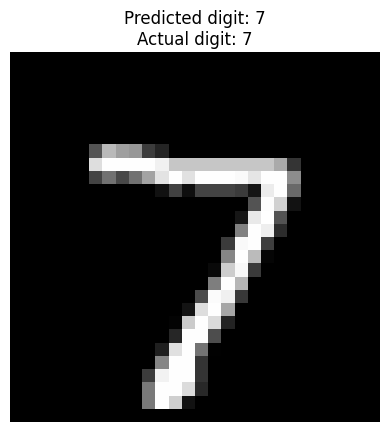

In [ ]:
plt.imshow(x_test[0].reshape(28, 28), cmap='gray')
plt.title (
    f"Predicted digit: {predictions[0].argmax()}\n"
    f"Actual digit: {y_test[0]}"
)
plt.axis('off')
plt.show()